# 05. Czy serce idzie w parze ze wskaźnikiem EEG? (COG-BCI, zadanie PVT)

Zadanie B3 z `docs/zadania.md` (COULD). Pytanie: **czy tętno i krótkoterminowa zmienność rytmu serca (HRV)
zmieniają się razem ze wskaźnikami zmęczenia i czujności z EEG?** To jest test założenia „EEG kalibruje, zegarek pilnuje”
w najprostszej możliwej formie: jeśli w tej samej osobie, w tym samym nagraniu, EEG i serce nie zmieniają się razem,
to tani czujnik nie zastąpi EEG bez dodatkowego modelu.

**Dane:** COG-BCI (Hinss i in., Zenodo 7413650): 29 osób, 3 sesje w odstępie tygodnia, EEG 63 kanały 500 Hz
oraz EKG (kanał `ECG1`, elektroda na lewym piątym międzyżebrzu). Bierzemy **zadanie PVT** (psychomotor vigilance task):
~10 minut monotonnego czekania na bodziec i naciśnięcia spacji, 90 prób. To najbliższe w tym zbiorze
„zmęczeniu czasem zadania”. Czas reakcji odczytujemy ze znaczników w samym zapisie EEG (13 = bodziec, 14 = reakcja,
wg `triggerlist.txt`), więc nie musimy zgadywać formatu plików `.mat`.

**Co liczymy w każdym 60-sekundowym odcinku PVT:**

| | Miara | Jak |
|---|---|---|
| EEG | (theta+alfa)/beta | log10, średnia z 8 kanałów; „wolny” wskaźnik zmęczenia z planu |
| EEG | alfa potyliczna | log10 mocy 8–12 Hz na O1/O2 |
| EEG | wyrazistość alfy | log10 stosunku 8–12 Hz do 5–7 i 14–16 Hz na O1/O2; „szybki” wskaźnik z planu |
| serce | tętno (HR) | z odstępów R–R z EKG |
| serce | RMSSD, SDNN | krótkoterminowa HRV z tych samych odstępów |
| zachowanie | mediana czasu reakcji, liczba „lapsów” (RT > 500 ms) | ze znaczników 13/14 |

EEG przetwarzamy potokiem projektu: nasze 8 kanałów, **przeliczenie do referencji Fp1** (jak w BrainAccess MINI,
patrz notebook 02), filtr 1–40 Hz, 250 Hz, okna 2 s z krokiem 1 s, odrzucenie okien z amplitudą szczyt-szczyt > 300 µV.

**Analiza jest wewnątrz osoby:** dla każdego nagrania liczymy korelację między odcinkami (ok. 10 punktów),
a potem patrzymy na rozkład tych korelacji. Dzięki temu różnice między ludźmi (ktoś ma po prostu wyższe tętno
i więcej alfy) nie tworzą pozornego związku.

**Ważne:** EKG z elektrod na klatce piersiowej w laboratorium to **nie jest** PPG z nadgarstka w zegarku.
Ten notebook mówi najwyżej, czy *najlepsza możliwa* informacja z serca idzie w parze z EEG.

In [1]:
%pip install -q mne remotezip neurokit2


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /tmp/claude-0/work/v/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import neurokit2 as nk
import numpy as np
import pandas as pd
from remotezip import RemoteZip
from scipy.signal import welch
from scipy.stats import spearmanr, wilcoxon

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200)

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300                 # drop 2 s windows whose peak-to-peak exceeds this (any channel)
SEG_S = 60                      # PVT segment length
BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}
RR_MIN, RR_MAX = 300, 2000      # plausible RR interval range [ms] (30-200 bpm)
RR_JUMP = 0.20                  # RR deviating > 20 % from the local median = artefact / missed or extra beat
LAPSE_MS = 500                  # PVT lapse threshold
MIN_SEGMENTS = 8                # a recording needs this many valid segments to enter correlations

SUBJECTS = [f"sub-{i:02d}" for i in range(1, 17)]   # up to sub-29
SESSIONS = ["S1", "S2", "S3"]

DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
RAW_DIR = DATA / "cogbci-pvt"          # extracted .set/.fdt, deleted after each recording
RES_DIR = DATA / "cogbci-pvt-results"  # small per-recording tables, kept so re-runs skip downloads
RES_DIR.mkdir(parents=True, exist_ok=True)
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"

## 1. Funkcje: EEG, EKG i czas reakcji w odcinkach

Detekcja załamków R: `neurokit2` (czyszczenie sygnału i detektor `neurokit`), bez automatycznej korekty artefaktów,
żeby było widać, ile odstępów R–R odrzucamy sami. Odstęp R–R uznajemy za artefakt, gdy jest poza zakresem 300–2000 ms
albo odbiega o ponad 20% od mediany sąsiednich 11 odstępów (gubione lub dodatkowe uderzenia). RMSSD liczymy tylko z par
sąsiednich poprawnych odstępów.

In [3]:
def pvt_events(raw):
    """Task start/end and per-trial stimulus time + reaction time (ms) from LSL triggers 13 (stimulus) / 14 (response)."""
    on, d = np.asarray(raw.annotations.onset), np.asarray(raw.annotations.description)
    stim, resp = on[d == "13"], on[d == "14"]
    trials = []
    for s in stim:
        nxt, nxt_stim = resp[resp > s], stim[stim > s]
        if len(nxt) and (not len(nxt_stim) or nxt[0] < nxt_stim[0]):
            trials.append((s, (nxt[0] - s) * 1000))
    t0 = on[d == "11"][0] if (d == "11").any() else stim[0]
    t1 = on[d == "15"][0] if (d == "15").any() else raw.times[-1]
    return t0, t1, pd.DataFrame(trials, columns=["t", "rt_ms"])


def eeg_windows(raw, ref="fp1"):
    """Project pipeline on our 8 channels: (Fp1 reference), 1-40 Hz, 250 Hz, 2 s windows / 1 s step, features per window."""
    r = raw.copy()
    if ref == "fp1":
        r.set_eeg_reference(["Fp1"], projection=False)
    r.pick(OUR_CH).reorder_channels(OUR_CH)
    r.filter(1.0, 40.0, fir_design="firwin", verbose=False).resample(FS)
    ep = mne.make_fixed_length_epochs(r, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)
    x = ep.get_data()
    ptp = np.ptp(x, axis=-1).max(1) * 1e6
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p * 1e12
    dfh = f[1] - f[0]
    pw = {b: p[:, :, (f >= lo) & (f <= hi)].sum(-1) * dfh for b, (lo, hi) in BANDS.items()}
    po = p[:, 6:8].mean(1)                                    # O1/O2 mean PSD
    band = lambda lo, hi: po[:, (f >= lo) & (f <= hi)].mean(1)
    return pd.DataFrame({
        "t": ep.events[:, 0] / FS,
        "alpha_occ": np.log10(pw["alpha"][:, 6:8].mean(1)),
        "tab_ratio": np.log10((pw["theta"].mean(1) + pw["alpha"].mean(1)) / pw["beta"].mean(1)),
        "alpha_prom": np.log10(band(8, 12) / np.sqrt(band(5, 7) * band(14, 16))),
        "bad": ptp > REJECT_UV,
    })


def r_peaks(raw):
    """Cleaned ECG (µV) and R-peak times (s)."""
    fs = raw.info["sfreq"]
    ecg = raw.copy().pick(["ECG1"]).get_data()[0] * 1e6
    clean = nk.ecg_clean(ecg, sampling_rate=fs, method="neurokit")
    med = np.median(clean)
    if med - np.percentile(clean, 0.5) > np.percentile(clean, 99.5) - med:
        clean = -clean                                        # inverted lead: make R waves positive
    _, info = nk.ecg_peaks(clean, sampling_rate=fs, method="neurokit", correct_artifacts=False)
    return clean, np.asarray(info["ECG_R_Peaks"]) / fs, fs


def rr_table(peaks_s):
    rr = np.diff(peaks_s) * 1000
    med = pd.Series(rr).rolling(11, center=True, min_periods=3).median().values
    ok = (rr >= RR_MIN) & (rr <= RR_MAX) & (np.abs(rr - med) <= RR_JUMP * med)
    return pd.DataFrame({"t": peaks_s[1:], "rr": rr, "ok": ok})


def heart_segment(R, a, b):
    s = R[(R.t >= a) & (R.t < b)]
    good = s[s.ok]
    pair_ok = s.ok.values[1:] & s.ok.values[:-1]
    d = np.diff(s.rr.values)[pair_ok]
    return dict(hr=60000 / good.rr.mean() if len(good) else np.nan,
                rmssd=np.sqrt(np.mean(d ** 2)) if len(d) > 10 else np.nan,
                sdnn=good.rr.std() if len(good) > 10 else np.nan,
                rr_bad_frac=1 - s.ok.mean() if len(s) else np.nan)


def process_recording(raw, sub, ses, ref="fp1"):
    t0, t1, trials = pvt_events(raw)
    W = eeg_windows(raw, ref)
    _, pk, _ = r_peaks(raw)
    R = rr_table(pk)
    rows = []
    for k in range(int((t1 - t0) // SEG_S)):
        a, b = t0 + k * SEG_S, t0 + (k + 1) * SEG_S
        w = W[(W.t >= a) & (W.t + WIN_S <= b)]
        wk = w[~w.bad]
        tr = trials[(trials.t >= a) & (trials.t < b)]
        row = dict(subject=sub, session=ses, seg=k, t_min=k * SEG_S / 60, n_win=len(w), n_clean=len(wk),
                   alpha_occ=wk.alpha_occ.mean(), tab_ratio=wk.tab_ratio.mean(), alpha_prom=wk.alpha_prom.mean(),
                   rt_med=tr.rt_ms.median() if len(tr) else np.nan,
                   lapses=int((tr.rt_ms > LAPSE_MS).sum()), n_trials=len(tr))
        row.update(heart_segment(R, a, b))
        rows.append(row)
    qc = dict(subject=sub, session=ses, dur_min=(t1 - t0) / 60, n_trials=len(trials), n_peaks=len(pk),
              rr_bad_pct=100 * (1 - R.ok.mean()), eeg_rej_pct=100 * W.bad.mean(),
              rt_median=trials.rt_ms.median())
    return pd.DataFrame(rows), qc, R.assign(subject=sub, session=ses)

## 2. Pobranie PVT i obróbka

Z każdego archiwum (~1,1 GB na osobę) wyciągamy przez zapytania HTTP z zakresem (`remotezip`) tylko `PVT.set` i `PVT.fdt`
(~77 MB na sesję), liczymy tabele i od razu kasujemy surowe pliki. Małe tabele wyników zostają w katalogu cache poza repo,
więc ponowne uruchomienie nie pobiera danych drugi raz. Dla porównania liczymy też wskaźniki EEG w oryginalnej referencji zbioru.
Dla pierwszego nagrania zachowujemy fragment EKG do wizualnej kontroli detekcji załamków R.

In [4]:
def fetch_pvt(sub, retries=4):
    """Extract only <sub>/.../ses-*/eeg/PVT.set|.fdt; returns {session: path_to_set}."""
    for attempt in range(retries):
        try:
            with RemoteZip(COG_URL.format(sub=sub)) as z:
                names = [n for n in z.namelist() if n.endswith(("/eeg/PVT.set", "/eeg/PVT.fdt"))]
                todo = [n for n in names if any(f"/ses-{s}/" in n for s in SESSIONS)
                        and not (RES_DIR / f"{sub}_{n.split('/ses-')[1][:2]}_seg.csv").exists()]
                for n in todo:
                    z.extract(n, RAW_DIR / sub)
            break
        except Exception as e:
            print(f"  {sub}: próba {attempt + 1} nieudana ({e}); czekam")
            time.sleep(30 * (attempt + 1))
    return {p.parent.parent.name[4:]: p for p in (RAW_DIR / sub).rglob("ses-*/eeg/PVT.set")}


ecg_example = None
t_start = time.time()
for sub in SUBJECTS:
    paths = fetch_pvt(sub)
    for ses, path in sorted(paths.items()):
        try:
            raw = mne.io.read_raw_eeglab(path, preload=True)
            S, qc, R = process_recording(raw, sub, ses, ref="fp1")
            So, _, _ = process_recording(raw, sub, ses, ref="orig")
            S = S.join(So[["alpha_occ", "tab_ratio", "alpha_prom"]].add_suffix("_origref"))
            S.to_csv(RES_DIR / f"{sub}_{ses}_seg.csv", index=False)
            pd.DataFrame([qc]).to_csv(RES_DIR / f"{sub}_{ses}_qc.csv", index=False)
            R.to_csv(RES_DIR / f"{sub}_{ses}_rr.csv", index=False)
            if ecg_example is None:
                clean, pk, fs = r_peaks(raw)
                ecg_example = dict(name=f"{sub} {ses}", clean=clean[: int(40 * fs)], fs=fs, pk=pk[pk < 40])
        except Exception as e:
            print(f"  {sub} {ses}: błąd obróbki ({e})")
    shutil.rmtree(RAW_DIR / sub, ignore_errors=True)
    print(f"{sub}: gotowe ({time.time() - t_start:.0f} s od startu)")

SEG = pd.concat([pd.read_csv(p) for p in sorted(RES_DIR.glob("*_seg.csv"))
                 if p.name.split("_")[0] in SUBJECTS], ignore_index=True)
QC = pd.concat([pd.read_csv(p) for p in sorted(RES_DIR.glob("*_qc.csv"))
                if p.name.split("_")[0] in SUBJECTS], ignore_index=True)
RR = pd.concat([pd.read_csv(p) for p in sorted(RES_DIR.glob("*_rr.csv"))
                if p.name.split("_")[0] in SUBJECTS], ignore_index=True)
print(f"{SEG.subject.nunique()} osób, {len(QC)} nagrań PVT, {len(SEG)} odcinków 60 s")

sub-01: gotowe (120 s od startu)


sub-02: gotowe (251 s od startu)


sub-03: gotowe (336 s od startu)


sub-04: gotowe (464 s od startu)


sub-05: gotowe (566 s od startu)


sub-06: gotowe (664 s od startu)


... (6 outputs left out)

sub-13: gotowe (1473 s od startu)


sub-14: gotowe (1579 s od startu)


sub-15: gotowe (1674 s od startu)


sub-16: gotowe (1730 s od startu)
16 osób, 48 nagrań PVT, 473 odcinków 60 s


## 3. Kontrola jakości EKG i EEG

Najpierw wzrokowo: fragment EKG z zaznaczonymi załamkami R. Potem tachogramy (odstępy R–R w czasie) wszystkich nagrań,
z artefaktami na czerwono: tu widać gubione uderzenia i fragmenty z odklejoną elektrodą.

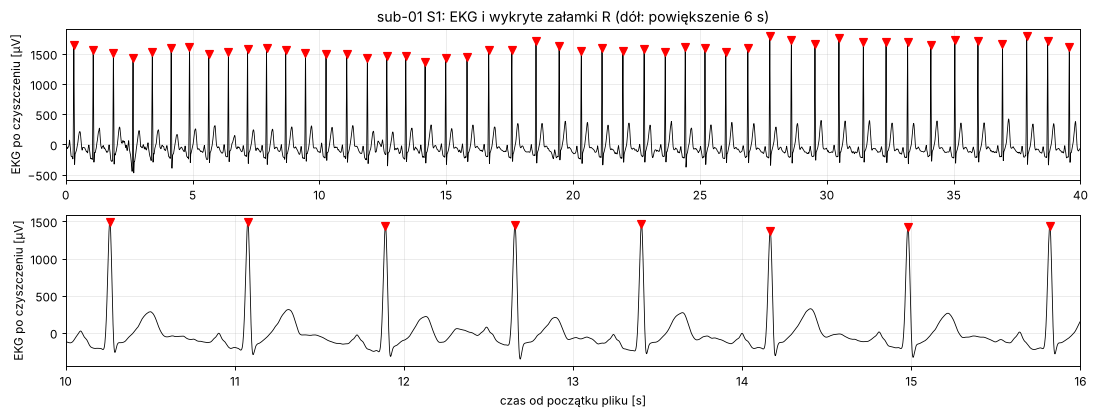

In [5]:
if ecg_example is None:   # results came from cache: re-fetch one recording only for the visual check
    with RemoteZip(COG_URL.format(sub=SUBJECTS[0])) as z:
        for n in z.namelist():
            if n.endswith(("/ses-S1/eeg/PVT.set", "/ses-S1/eeg/PVT.fdt")):
                z.extract(n, RAW_DIR / SUBJECTS[0])
    raw = mne.io.read_raw_eeglab(next((RAW_DIR / SUBJECTS[0]).rglob("ses-S1/eeg/PVT.set")), preload=True)
    clean, pk, fs = r_peaks(raw)
    ecg_example = dict(name=f"{SUBJECTS[0]} S1", clean=clean[: int(40 * fs)], fs=fs, pk=pk[pk < 40])
    shutil.rmtree(RAW_DIR / SUBJECTS[0], ignore_errors=True)

e = ecg_example
t = np.arange(len(e["clean"])) / e["fs"]
fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for ax, (a, b) in zip(axes, [(0, 40), (10, 16)]):
    m = (t >= a) & (t < b)
    ax.plot(t[m], e["clean"][m], lw=0.7, color="k")
    pk = e["pk"][(e["pk"] >= a) & (e["pk"] < b)]
    ax.plot(pk, e["clean"][(pk * e["fs"]).astype(int)], "rv", ms=6)
    ax.set_xlim(a, b); ax.set_ylabel("EKG po czyszczeniu [µV]")
axes[0].set_title(f"{e['name']}: EKG i wykryte załamki R (dół: powiększenie 6 s)")
axes[1].set_xlabel("czas od początku pliku [s]")
plt.tight_layout(); plt.show()

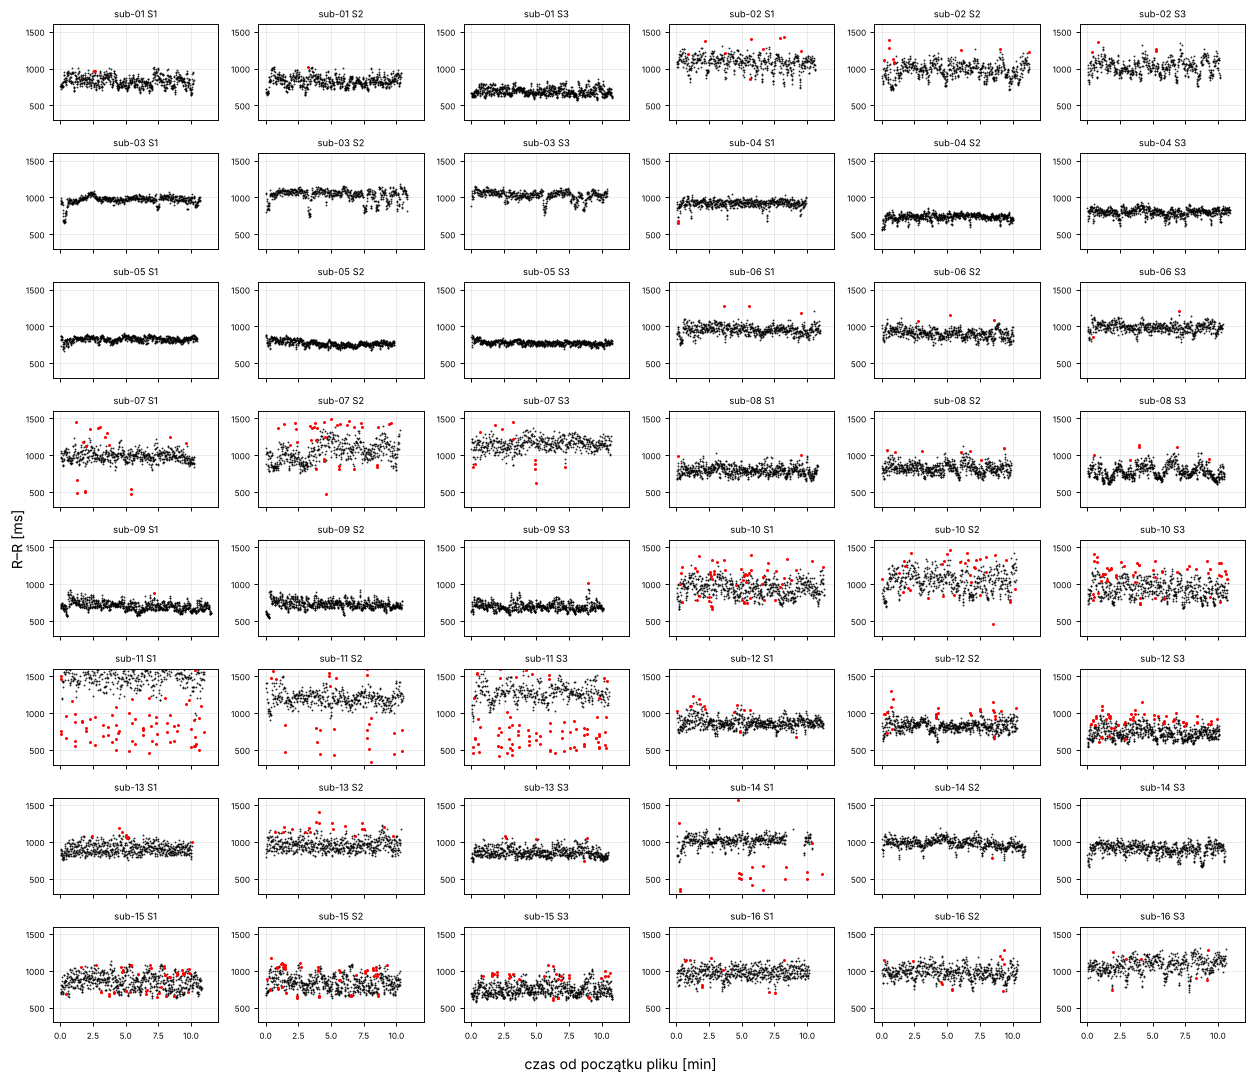

In [6]:
recs = QC[["subject", "session"]].values.tolist()
ncol = 6
nrow = int(np.ceil(len(recs) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 1.6 * nrow), sharex=True)
for ax, (sub, ses) in zip(axes.flat, recs):
    r = RR[(RR.subject == sub) & (RR.session == ses)]
    ax.plot(r.t / 60, r.rr, ".", ms=1, color="k")
    ax.plot(r.t[~r.ok] / 60, r.rr[~r.ok], ".", ms=3, color="red")
    ax.set_ylim(300, 1600); ax.set_title(f"{sub} {ses}", fontsize=8); ax.tick_params(labelsize=7)
for ax in axes.flat[len(recs):]:
    ax.axis("off")
fig.supylabel("R–R [ms]"); fig.supxlabel("czas od początku pliku [min]")
plt.tight_layout(); plt.show()

In [7]:
print("Na nagranie (mediana [min–max]):")
for col, name in [("dur_min", "długość PVT [min]"), ("n_trials", "próby PVT"), ("rr_bad_pct", "odrzucone R–R [%]"),
                  ("eeg_rej_pct", "odrzucone okna EEG [%]"), ("rt_median", "mediana RT [ms]")]:
    print(f"  {name:28s} {QC[col].median():7.1f}  [{QC[col].min():.1f}–{QC[col].max():.1f}]")
QC.sort_values("rr_bad_pct", ascending=False).head(8).round(1)

Na nagranie (mediana [min–max]):
  długość PVT [min]               10.3  [9.7–11.2]
  próby PVT                       90.0  [84.0–90.0]
  odrzucone R–R [%]                0.9  [0.0–15.5]
  odrzucone okna EEG [%]           5.5  [0.0–62.7]
  mediana RT [ms]                319.0  [255.0–385.0]


,subject,session,dur_min,n_trials,n_peaks,rr_bad_pct,eeg_rej_pct,rt_median
32,sub-11,S3,10.4,84,529,15.5,26.7,300.0
30,sub-11,S1,10.7,89,481,15.4,18.6,296.0
29,sub-10,S3,10.6,90,686,8.3,2.0,312.0
27,sub-10,S1,11.1,90,713,7.9,0.9,321.0
39,sub-14,S1,11.2,90,549,7.1,60.8,323.0
35,sub-12,S3,10.0,90,817,7.0,2.0,311.0
43,sub-15,S2,10.1,90,733,6.8,18.0,336.0
19,sub-07,S2,10.0,90,588,6.0,13.4,255.0


Reguły dopuszczenia odcinka 60 s do analizy: co najmniej 20 czystych okien EEG (z ok. 59), co najwyżej 10% odrzuconych
odstępów R–R i co najmniej 3 próby PVT. Nagranie wchodzi do korelacji, gdy ma co najmniej 8 dopuszczonych odcinków.

In [8]:
SEG["valid"] = (SEG.n_clean >= 20) & (SEG.rr_bad_frac <= 0.10) & (SEG.n_trials >= 3) & SEG.rmssd.notna()
SEG["rec"] = SEG.subject + "_" + SEG.session
nvalid = SEG.groupby("rec").valid.sum()
good_recs = nvalid[nvalid >= MIN_SEGMENTS].index
V = SEG[SEG.valid & SEG.rec.isin(good_recs)].copy()
print(f"odcinki dopuszczone: {SEG.valid.sum()} z {len(SEG)}")
print(f"nagrania w analizie: {len(good_recs)} z {SEG.rec.nunique()}, osoby: {V.subject.nunique()}, odcinki: {len(V)}")
print("odrzucone nagrania:", sorted(set(SEG.rec) - set(good_recs)))

odcinki dopuszczone: 429 z 473
nagrania w analizie: 41 z 48, osoby: 16, odcinki: 393
odrzucone nagrania: ['sub-07_S2', 'sub-10_S3', 'sub-11_S1', 'sub-11_S3', 'sub-14_S1', 'sub-14_S2', 'sub-15_S2']


## 4. Trend w czasie zadania

Każdą miarę standaryzujemy wewnątrz nagrania (z-score po odcinkach), potem uśredniamy krzywe. Dodatkowo dla każdego
nagrania liczymy nachylenie (zmiana z-score na minutę) i sprawdzamy na poziomie osób (średnia z sesji), czy jest różne od zera
(test Wilcoxona).

In [9]:
MEAS = {"tab_ratio": "(θ+α)/β EEG", "alpha_occ": "alfa O1/O2", "alpha_prom": "wyrazistość alfy",
        "hr": "tętno", "rmssd": "RMSSD", "sdnn": "SDNN", "rt_med": "mediana RT", "lapses": "lapsy (RT>500 ms)"}
Z = V.copy()
for c in list(MEAS) + ["alpha_occ_origref", "tab_ratio_origref", "alpha_prom_origref"]:
    g = Z.groupby("rec")[c]
    Z[c] = (Z[c] - g.transform("mean")) / g.transform("std").replace(0, np.nan)

rows = []
for c, name in MEAS.items():
    slopes = Z.groupby(["subject", "rec"]).apply(lambda d: np.polyfit(d.t_min, d[c], 1)[0] if d[c].notna().sum() > 3 else np.nan)
    per_sub = slopes.groupby(level=0).mean().dropna()
    p = wilcoxon(per_sub).pvalue if len(per_sub) > 5 else np.nan
    raw_change = V.groupby("rec").apply(lambda d: d[c][d.t_min >= d.t_min.max() - 2].mean() - d[c][d.t_min <= 2].mean())
    rows.append(dict(miara=name, nachylenie_z_na_min=per_sub.median(), osoby_rosnace=f"{(per_sub > 0).sum()}/{len(per_sub)}",
                     p_wilcoxon=p, zmiana_koniec_minus_poczatek=raw_change.median()))
TREND = pd.DataFrame(rows)
print("zmiana_koniec_minus_poczatek: mediana po nagraniach, średnia z ostatnich 3 minus pierwszych 3 odcinków, w jednostkach miary")
TREND.round(3)

zmiana_koniec_minus_poczatek: mediana po nagraniach, średnia z ostatnich 3 minus pierwszych 3 odcinków, w jednostkach miary


,miara,nachylenie_z_na_min,osoby_rosnace,p_wilcoxon,zmiana_koniec_minus_poczatek
0,(θ+α)/β EEG,-0.040,8/16,0.323,-0.039
1,alfa O1/O2,0.111,15/16,0.003,0.048
2,wyrazistość alfy,0.029,10/16,1.000,-0.014
3,tętno,0.093,13/16,0.008,1.395
4,RMSSD,-0.044,4/16,0.083,-1.354
5,SDNN,-0.019,7/16,0.433,0.135
6,mediana RT,0.113,14/16,0.000,14.000
7,lapsy (RT>500 ms),0.063,9/13,0.048,0.000


## 5. Czy EEG i serce zmieniają się razem? Korelacje wewnątrz nagrania

Dla każdego nagrania: korelacja Spearmana między odcinkami (ok. 10 punktów). Dwie wersje:

- **surowa:** obejmuje wspólny trend w czasie (jeśli obie miary po prostu dryfują w trakcie zadania, wyjdzie korelacja);
- **bez trendu:** z obu miar usuwamy liniowy trend w czasie i korelujemy reszty, czyli pytamy, czy *wahania* minuta po minucie idą w parze.

Na poziomie osoby uśredniamy korelacje z sesji (przez transformację Fishera), potem test Wilcoxona względem zera po osobach.

In [10]:
def detrend(d, c):
    y = d[c].values
    m = ~np.isnan(y)
    out = np.full_like(y, np.nan, dtype=float)
    if m.sum() > 3:
        out[m] = y[m] - np.polyval(np.polyfit(d.t_min.values[m], y[m], 1), d.t_min.values[m])
    return out


PAIRS = [("tab_ratio", "hr"), ("tab_ratio", "rmssd"), ("tab_ratio", "sdnn"),
         ("alpha_occ", "hr"), ("alpha_occ", "rmssd"), ("alpha_prom", "hr"), ("alpha_prom", "rmssd"),
         ("tab_ratio", "rt_med"), ("alpha_occ", "rt_med"), ("alpha_prom", "rt_med"),
         ("hr", "rt_med"), ("rmssd", "rt_med"),
         ("tab_ratio_origref", "hr"), ("tab_ratio_origref", "rmssd")]
rec_rows = []
for rec, d in V.groupby("rec"):
    d = d.sort_values("t_min")
    for a, b in PAIRS:
        r_raw = spearmanr(d[a], d[b], nan_policy="omit").statistic
        r_dt = spearmanr(detrend(d, a), detrend(d, b), nan_policy="omit").statistic
        rec_rows.append(dict(rec=rec, subject=d.subject.iloc[0], pair=f"{a} ~ {b}", r_raw=r_raw, r_detr=r_dt))
RC = pd.DataFrame(rec_rows)


def subj_level(col):
    zf = np.arctanh(RC[col].clip(-0.999, 0.999))
    return np.tanh(zf.groupby([RC.pair, RC.subject]).mean())


rows = []
for col in ("r_raw", "r_detr"):
    S_ = subj_level(col)
    for pair in dict.fromkeys(RC.pair):
        v = S_.loc[pair].dropna()
        rv = RC[RC.pair == pair][col].dropna()
        rows.append(dict(para=pair, wersja=col, n_osob=len(v), mediana_r_osoby=v.median(),
                         q25=v.quantile(0.25), q75=v.quantile(0.75), dodatnie=f"{(v > 0).sum()}/{len(v)}",
                         p_wilcoxon=wilcoxon(v).pvalue, mediana_r_nagrania=rv.median(), n_nagran=len(rv)))
CORR = pd.DataFrame(rows)
CORR.round(3)

,para,wersja,n_osob,mediana_r_osoby,q25,q75,dodatnie,p_wilcoxon,mediana_r_nagrania,n_nagran
0,tab_ratio ~ hr,r_raw,16,-0.057,-0.315,0.011,4/16,0.117,-0.042,41
1,tab_ratio ~ rmssd,r_raw,16,0.155,-0.051,0.317,10/16,0.034,0.139,41
2,tab_ratio ~ sdnn,r_raw,16,0.102,-0.054,0.160,9/16,0.404,0.067,41
3,alpha_occ ~ hr,r_raw,16,0.093,-0.037,0.353,11/16,0.144,0.067,41
4,alpha_occ ~ rmssd,r_raw,16,-0.124,-0.362,0.066,5/16,0.117,-0.115,41
5,alpha_prom ~ hr,r_raw,16,0.001,-0.097,0.097,8/16,0.940,0.017,41
6,alpha_prom ~ rmssd,r_raw,16,-0.159,-0.351,0.052,6/16,0.159,-0.176,41
7,tab_ratio ~ rt_med,r_raw,16,0.056,-0.170,0.195,9/16,0.528,0.048,41
8,alpha_occ ~ rt_med,r_raw,16,0.154,-0.138,0.364,11/16,0.175,0.167,41
9,alpha_prom ~ rt_med,r_raw,16,-0.018,-0.337,0.203,6/16,0.528,-0.188,41


### Wszystkie odcinki razem (z-score wewnątrz nagrania)

Dla porównania: korelacja na wszystkich odcinkach naraz, po standaryzacji wewnątrz nagrania. Odcinki tego samego nagrania
nie są niezależne, więc wartości *p* tutaj nie podajemy; liczy się wielkość *r*.

In [11]:
for a, b in [("tab_ratio", "hr"), ("tab_ratio", "rmssd"), ("alpha_occ", "hr"), ("alpha_prom", "hr"),
             ("tab_ratio", "rt_med"), ("hr", "rt_med"), ("rmssd", "rt_med")]:
    m = Z[[a, b]].dropna()
    print(f"{MEAS[a]:>16s} ~ {MEAS[b]:<12s} r Spearmana = {spearmanr(m[a], m[b]).statistic:+.2f}  (n odcinków = {len(m)})")

     (θ+α)/β EEG ~ tętno        r Spearmana = -0.10  (n odcinków = 393)
     (θ+α)/β EEG ~ RMSSD        r Spearmana = +0.13  (n odcinków = 393)
      alfa O1/O2 ~ tętno        r Spearmana = +0.12  (n odcinków = 393)
wyrazistość alfy ~ tętno        r Spearmana = +0.00  (n odcinków = 393)
     (θ+α)/β EEG ~ mediana RT   r Spearmana = +0.05  (n odcinków = 393)
           tętno ~ mediana RT   r Spearmana = +0.08  (n odcinków = 393)
           RMSSD ~ mediana RT   r Spearmana = -0.20  (n odcinków = 393)


## 6. Wykres na slajd

Lewo: trend w czasie zadania PVT (z-score wewnątrz nagrania, średnia ± błąd standardowy po nagraniach).
Prawo: korelacje wewnątrz osoby (każda kropka to jedna osoba, średnia z jej sesji), pełne kropki = surowe,
puste = po usunięciu trendu w czasie.

../../docs/img/eeg-vs-heart-cogbci-pvt.png 151 kB


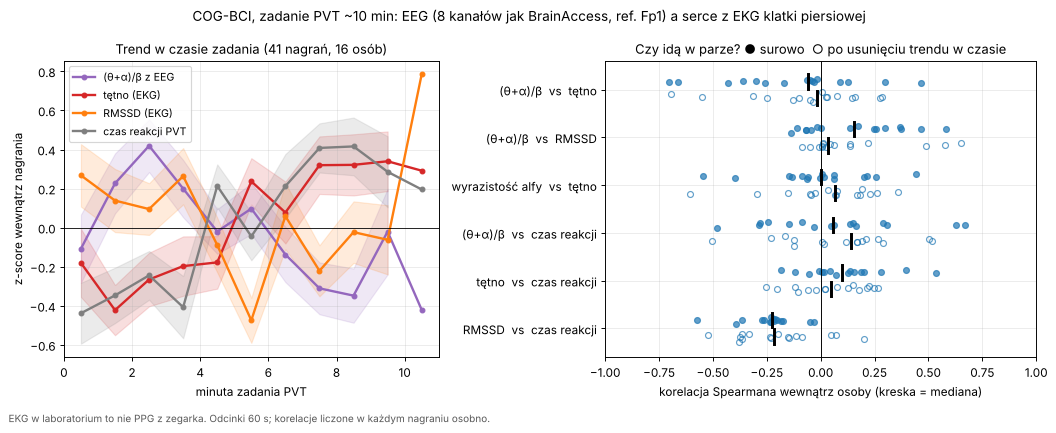

In [12]:
FIG_PATH = Path("../../docs/img/eeg-vs-heart-cogbci-pvt.png")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1, 1.15]})
curves = [("tab_ratio", "(θ+α)/β z EEG", "tab:purple"), ("hr", "tętno (EKG)", "tab:red"),
          ("rmssd", "RMSSD (EKG)", "tab:orange"), ("rt_med", "czas reakcji PVT", "tab:gray")]
for c, lab, col in curves:
    g = Z.groupby("seg")[c]
    m, se = g.mean(), g.sem()
    x = m.index + 0.5
    a1.plot(x, m, "-o", color=col, label=lab, ms=4, lw=2)
    a1.fill_between(x, m - se, m + se, color=col, alpha=0.15)
a1.axhline(0, color="k", lw=0.7)
a1.set_xlabel("minuta zadania PVT"); a1.set_ylabel("z-score wewnątrz nagrania")
a1.set_title(f"Trend w czasie zadania ({len(good_recs)} nagrań, {V.subject.nunique()} osób)", fontsize=11)
a1.legend(fontsize=9, loc="upper left")

show = [("tab_ratio ~ hr", "(θ+α)/β  vs  tętno"), ("tab_ratio ~ rmssd", "(θ+α)/β  vs  RMSSD"),
        ("alpha_prom ~ hr", "wyrazistość alfy  vs  tętno"), ("tab_ratio ~ rt_med", "(θ+α)/β  vs  czas reakcji"),
        ("hr ~ rt_med", "tętno  vs  czas reakcji"), ("rmssd ~ rt_med", "RMSSD  vs  czas reakcji")]
rng = np.random.default_rng(1)
S_raw, S_dt = subj_level("r_raw"), subj_level("r_detr")
for i, (pair, lab) in enumerate(show):
    for S_, off, fc in ((S_raw, -0.17, "tab:blue"), (S_dt, 0.17, "none")):
        v = S_.loc[pair].dropna().values
        a2.plot(v, i + off + rng.normal(0, 0.04, len(v)), "o", ms=5, mec="tab:blue", mfc=fc, alpha=0.7)
        a2.plot([np.median(v)] * 2, [i + off - 0.15, i + off + 0.15], color="k", lw=2.5)
a2.axvline(0, color="k", lw=0.8)
a2.set_yticks(range(len(show)), [s[1] for s in show]); a2.invert_yaxis()
a2.set_xlim(-1, 1); a2.set_xlabel("korelacja Spearmana wewnątrz osoby (kreska = mediana)")
a2.set_title("Czy idą w parze? ● surowo  ○ po usunięciu trendu w czasie", fontsize=11)
fig.suptitle("COG-BCI, zadanie PVT ~10 min: EEG (8 kanałów jak BrainAccess, ref. Fp1) a serce z EKG klatki piersiowej",
             fontsize=11.5)
fig.text(0.01, 0.005, "EKG w laboratorium to nie PPG z zegarka. Odcinki 60 s; korelacje liczone w każdym nagraniu osobno.",
         fontsize=8.5, color="0.35")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if FIG_PATH.parent.exists():
    fig.savefig(FIG_PATH, dpi=85)
    print(FIG_PATH, f"{FIG_PATH.stat().st_size / 1024:.0f} kB")
plt.show()

## 7. Wnioski

Wszystkie liczby pochodzą z tabel powyżej (16 osób, 41 z 48 nagrań PVT po kontroli jakości, 393 odcinki po 60 s).

**W dwóch zdaniach.** W tym zbiorze serce i wskaźniki EEG **nie idą w parze**: korelacje wewnątrz osoby między wskaźnikami EEG a tętnem lub RMSSD są słabe (mediany |r| do 0,16) i w większości nieodróżnialne od zera. Jedyny wyraźny związek serca z czujnością to RMSSD a czas reakcji: im niższa zmienność rytmu w danej minucie, tym wolniejsze reakcje (mediana r = −0,23, kierunek ujemny u 16 z 16 osób; po usunięciu trendu w czasie −0,22, u 13 z 16).

**Co się dzieje w czasie 10 minut monotonnego zadania.**
- Czas reakcji rośnie u 14 z 16 osób (mediana +14 ms między początkiem a końcem), czyli czujność rzeczywiście spada.
- Moc alfy potylicznej rośnie u 15 z 16 osób (p = 0,003). To zgadza się z naszym głównym wskaźnikiem.
- Tętno rośnie u 13 z 16 osób (mediana +1,4 uderzenia na minutę, p = 0,008). RMSSD ma tendencję spadkową (rośnie tylko u 4 z 16, p = 0,08).
- Wyrazistość alfy i (theta+alfa)/beta nie mają spójnego trendu (10/16 i 8/16 osób).

**EEG a serce, minuta po minucie.**
- (theta+alfa)/beta a RMSSD: mediana r = 0,16 (dodatnie u 10 z 16, p = 0,03), po usunięciu trendu 0,03. To najsilniejsza para EEG–serce i nadal jest słaba.
- Alfa potyliczna a tętno: mediana r = 0,09 (11 z 16, p = 0,14). Wyrazistość alfy a tętno: 0,00.
- Wskaźniki EEG a czas reakcji: też słabo (alfa potyliczna 0,15, p = 0,18).

**Co to znaczy dla hasła „EEG kalibruje, zegarek pilnuje”.** Te dane go nie potwierdzają w prostej postaci: z minuty na minutę sygnał serca nie odtwarza wskaźnika EEG. Wspierają natomiast słabszą tezę, że zmienność rytmu serca niesie własną, niezależną informację o spadku czujności (związek z czasem reakcji). Na slajdzie można uczciwie powiedzieć „HRV i EEG reagują na to samo zadanie, ale nie są zamienne”, a nie „zegarek zastąpi EEG”.

**Ograniczenia.**
- EKG z klatki piersiowej w laboratorium to nie PPG z nadgarstka. Zegarek będzie miał gorszą jakość odstępów R–R, zwłaszcza przy ruchu.
- Odcinki 60 s dają ok. 10 punktów na nagranie, więc pojedyncze korelacje są bardzo niepewne. RMSSD z 60 s to dolna granica sensownej długości.
- 10 minut PVT to krótki spadek czujności, nie zmęczenie po wielu godzinach pracy. Związki mogą wyglądać inaczej w skali zmiany roboczej.
- Elektrody żelowe, EEG przeliczone do referencji Fp1, 7 nagrań odrzuconych za jakość EKG lub EEG.
- Policzono wiele par bez korekty na wielokrotne porównania, więc pojedynczych wartości p w okolicy 0,03 nie należy traktować jako dowodu.